# Modularity on the Karate Club Graph

**DSC212 — Graph Theory Module**  
**Name:** Divyansh Trivedi  
**Roll No.:** IMS25073

This notebook develops the modularity framework and implements recursive spectral bisection on Zachary's Karate Club graph. It then removes edges between detected communities and studies the evolution of four node-level network metrics.

## 1. Problem setup: the Karate Club graph

The Karate Club network contains 34 members represented as vertices and 78 observed friendship edges. The assignment uses this graph to study whether connectivity patterns can reveal groups of vertices that are more densely connected to one another than a degree-preserving random baseline would predict.

The goal is to partition the graph using spectral modularity, visualize the partition after every successful split round, and measure how node centrality and local clustering change as inter-community edges are removed.

## 2. From the graph to its adjacency matrix

For an undirected, unweighted graph, the adjacency matrix $A$ records whether each pair of vertices is connected. Its entry $A_{ij}$ is 1 when an edge joins vertices $i$ and $j$, and 0 otherwise. Since the graph is undirected, $A$ is symmetric; the degree of vertex $i$ is the sum of row $i$.

We construct the graph, fix one node ordering, and use that same ordering for every matrix and vector in the notebook. The NetworkX dataset also stores an edge `weight` attribute, but the handout defines a binary adjacency matrix, so we explicitly ignore those weights when creating $A$.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

%matplotlib inline

# Build the Zachary Karate Club graph.
G = nx.karate_club_graph()
nodes = list(G.nodes())
node_index = {node: i for i, node in enumerate(nodes)}

# Construct A using the fixed node ordering.
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)
n = G.number_of_nodes()
m = G.number_of_edges()

# Degree vector: k_i is the sum of row i of A.
k = A.sum(axis=1)

print(f"Number of vertices (n): {n}")
print(f"Number of edges (m): {m}")
print(f"Adjacency matrix shape: {A.shape}")
print(f"Degree vector shape: {k.shape}")
print(f"Sum of degrees: {int(k.sum())} = 2m = {2 * m}")
print(f"Adjacency matrix is symmetric: {np.allclose(A, A.T)}")
print(f"Diagonal entries are zero: {np.allclose(np.diag(A), 0)}")
print(f"All adjacency entries are binary: {set(np.unique(A)).issubset({0.0, 1.0})}")

Number of vertices (n): 34
Number of edges (m): 78
Adjacency matrix shape: (34, 34)
Degree vector shape: (34,)
Sum of degrees: 156 = 2m = 156
Adjacency matrix is symmetric: True
Diagonal entries are zero: True
All adjacency entries are binary: True


## Notation and Dimensions

<table>
<thead>
<tr><th>Object</th><th>Symbol</th><th>Dimension</th><th>Meaning</th></tr>
</thead>
<tbody>
<tr><td>Adjacency matrix</td><td>A</td><td>n × n</td><td>Represents the observed edges</td></tr>
<tr><td>Degree vector</td><td>k</td><td>n × 1</td><td>Row sums of A</td></tr>
<tr><td>Expected-edge matrix</td><td>P</td><td>n × n</td><td>Expected connections under the null model</td></tr>
<tr><td>Global modularity matrix</td><td>B</td><td>n × n</td><td>Difference between observed and expected connections</td></tr>
<tr><td>Restricted modularity matrix</td><td>B<sup>(C)</sup></td><td>|C| × |C|</td><td>Principal submatrix of B indexed by community C</td></tr>
<tr><td>Split label vector</td><td>s</td><td>|C| × 1</td><td>Assigns each node in C a label from {−1, +1}</td></tr>
</tbody>
</table>

**Expected-edge matrix:**

$$
P = \frac{\mathbf{k}\mathbf{k}^{\top}}{2m}
$$


In [2]:
print("First 8 x 8 block of the adjacency matrix A:")
print(A[:8, :8].astype(int))

print("\nDegree vector k, in node order 0 through 33:")
print(k.astype(int))

First 8 x 8 block of the adjacency matrix A:
[[0 1 1 1 1 1 1 1]
 [1 0 1 1 0 0 0 1]
 [1 1 0 1 0 0 0 1]
 [1 1 1 0 0 0 0 1]
 [1 0 0 0 0 0 1 0]
 [1 0 0 0 0 0 1 0]
 [1 0 0 0 1 1 0 0]
 [1 1 1 1 0 0 0 0]]

Degree vector k, in node order 0 through 33:
[16  9 10  6  3  4  4  4  5  2  3  1  2  5  2  2  2  2  2  3  2  2  2  5
  3  3  2  4  3  4  4  6 12 17]


## 3. The null model and the global modularity matrix

A cut with few cross-group edges is not automatically meaningful: a small group can be isolated simply because its vertices have low degree. Modularity addresses this by comparing observed edges with the expected number of edges under a random null model that preserves the degree sequence.

In the stub interpretation, vertex $i$ contributes $k_i$ half-edges and there are $2m$ half-edges in total. The expected adjacency contribution for a pair $(i,j)$ is $\frac{k_i k_j}{2m}$. Arranging these expectations into a matrix gives the expected-edge matrix $P$:

$$
P = \frac{\mathbf{k}\mathbf{k}^{\top}}{2m}.
$$

The global modularity matrix is the difference between the observed adjacency matrix and this expected-edge matrix:

$$
B = A - P = A - \frac{\mathbf{k}\mathbf{k}^{\top}}{2m}.
$$

In [3]:
# Expected edge-count matrix under the degree-preserving null model.
P = np.outer(k, k) / (2 * m)

# Construct the global modularity matrix ONCE.
B = A - P

print(f"Expected-edge matrix shape: {P.shape}")
print(f"Global modularity matrix B shape: {B.shape}")
print(f"Maximum symmetry error in B: {np.max(np.abs(B - B.T)):.2e}")

print("\nFirst 5 x 5 block of the expected-edge matrix P:")
print(np.round(P[:5, :5], 3))

print("\nFirst 5 x 5 block of the global modularity matrix B:")
print(np.round(B[:5, :5], 3))

Expected-edge matrix shape: (34, 34)
Global modularity matrix B shape: (34, 34)
Maximum symmetry error in B: 0.00e+00

First 5 x 5 block of the expected-edge matrix P:
[[1.641 0.923 1.026 0.615 0.308]
 [0.923 0.519 0.577 0.346 0.173]
 [1.026 0.577 0.641 0.385 0.192]
 [0.615 0.346 0.385 0.231 0.115]
 [0.308 0.173 0.192 0.115 0.058]]

First 5 x 5 block of the global modularity matrix B:
[[-1.641  0.077 -0.026  0.385  0.692]
 [ 0.077 -0.519  0.423  0.654 -0.173]
 [-0.026  0.423 -0.641  0.615 -0.192]
 [ 0.385  0.654  0.615 -0.231 -0.115]
 [ 0.692 -0.173 -0.192 -0.115 -0.058]]


### Why the global matrix is symmetric

The adjacency matrix is symmetric because the network is undirected. The outer product $\mathbf{k}\mathbf{k}^{\top}$ is also symmetric, so their difference $B$ is a real symmetric matrix. This matters because a real symmetric matrix has real eigenvalues and an orthonormal eigenbasis, allowing us to use `numpy.linalg.eigh` reliably.

### A useful property: the all-ones vector

Let $\mathbf{1}$ denote the vector whose entries are all 1. Since $A\mathbf{1}=\mathbf{k}$ and $\mathbf{k}^{\top}\mathbf{1}=2m$, the global modularity matrix satisfies $B\mathbf{1}=0$. Thus, the all-vertices-in-one-group assignment has modularity zero under the handout's convention.

In [4]:
ones = np.ones(n)

row_sum_residual = B @ ones
trivial_modularity = (ones @ B @ ones) / (4 * m)

print(f"||B 1||_infinity: {np.max(np.abs(row_sum_residual)):.2e}")
print(f"Modularity of the trivial all-in-one assignment: {trivial_modularity:.2e}")

||B 1||_infinity: 8.88e-16
Modularity of the trivial all-in-one assignment: 8.72e-18


## 4. Modularity as a partition quality function

For a two-community division, assign each vertex a label $s_i \in \{+1,-1\}$. The vector $s$ records the two sides of the partition. The modularity score for this division, following the handout's convention, is

$$
Q(s) = \frac{1}{4m}s^{\top}Bs.
$$

A positive score indicates that the proposed division places more edge weight within groups than expected under the degree-preserving null model. Community detection can therefore be viewed as finding a label vector that makes this quadratic form large.

### Why the exact discrete optimization is difficult

There are $2^n$ possible sign assignments for $n$ vertices, so checking every partition becomes impractical even for moderately sized graphs. Spectral modularity uses a continuous relaxation: instead of restricting each entry of $s$ to $\pm1$, it allows real-valued vectors with unit Euclidean norm.

The relaxed problem is to maximize $x^{\top}Bx$ subject to $\lVert x\rVert_2=1$. By the Rayleigh–Ritz theorem, the maximum is the largest eigenvalue of $B$ and is attained by its leading eigenvector.

### Rayleigh–Ritz result in one step

Because $B$ is real and symmetric, write a unit vector in its orthonormal eigenbasis as $x=\sum_i \alpha_i u_i$, where $\sum_i \alpha_i^2=1$. Then $x^{\top}Bx=\sum_i \alpha_i^2\lambda_i\leq \lambda_{\max}\sum_i \alpha_i^2=\lambda_{\max}$, with equality for a leading eigenvector. This is why the leading eigenvector is the continuous solution used by the spectral method.

### Turning the leading eigenvector into a two-way split

The leading eigenvector gives a soft assignment: positive entries lean toward one group and nonpositive entries toward the other. We convert it into a discrete partition using the sign rule $s_i=+1$ when $u_i>0$, and $s_i=-1$ otherwise.

The largest eigenvalue indicates whether the relaxed problem has a positive direction. In this assignment, a candidate is split only when its largest eigenvalue is greater than $10^{-10}$, as specified in the implementation requirements.

## 5. Restricting the global matrix to a candidate community

Suppose a current community is a subset of vertices $C\subseteq V$. Its restricted modularity matrix is the principal submatrix formed by selecting the rows and columns of the **original global** matrix $B$ whose node IDs belong to $C$.

This is implemented with `B[np.ix_(indices, indices)]`. We do not rebuild a modularity matrix from the induced subgraph: all recursive tests use slices of the one global $B$ computed above, retaining the original degrees and denominator $2m$.

In [5]:
# Demonstrate the restricted-matrix operation on a small example community.
example_community = nodes[:6]
example_indices = [node_index[node] for node in example_community]
B_example = B[np.ix_(example_indices, example_indices)]

print("Example community node IDs:", example_community)
print("Restricted matrix shape:", B_example.shape)
print("Restricted matrix is symmetric:", np.allclose(B_example, B_example.T))
print("\nRestricted modularity submatrix:")
print(np.round(B_example, 3))

Example community node IDs: [0, 1, 2, 3, 4, 5]
Restricted matrix shape: (6, 6)
Restricted matrix is symmetric: True

Restricted modularity submatrix:
[[-1.641  0.077 -0.026  0.385  0.692  0.59 ]
 [ 0.077 -0.519  0.423  0.654 -0.173 -0.231]
 [-0.026  0.423 -0.641  0.615 -0.192 -0.256]
 [ 0.385  0.654  0.615 -0.231 -0.115 -0.154]
 [ 0.692 -0.173 -0.192 -0.115 -0.058 -0.077]
 [ 0.59  -0.231 -0.256 -0.154 -0.077 -0.103]]


### Eigenvalue stopping criterion

For a candidate community $C$, the handout considers the leading eigenpair $(\lambda_{\max}^{(C)},u_{\max}^{(C)})$ of its restricted matrix. If $\lambda_{\max}^{(C)}$ does not exceed the numerical threshold, the candidate is not split; otherwise, the leading eigenvector is converted into the two sign groups.

A practical edge case occurs when every eigenvector entry has the same sign. The prescribed sign rule would then create an empty side, which is not a valid bipartition. The implementation retains and reports such a candidate separately instead of silently creating an empty community or changing the sign rule.

### Why a nonpositive leading eigenvalue stops a candidate

For any vector $x$, the Rayleigh–Ritz bound gives

$$
x^{\top}B^{(C)}x \leq \lambda_{\max}^{(C)}\lVert x\rVert_2^2.
$$

A sign vector has $\lVert s\rVert_2^2 = |C|$, and the change in modularity for that split is

$$
\Delta Q = \frac{1}{4m}s^{\top}B^{(C)}s.
$$

Therefore, when $\lambda_{\max}^{(C)} \leq 0$, every possible sign split has $\Delta Q \leq 0$. In the implementation, the numerical stopping test is slightly stricter: a candidate is not split unless $\lambda_{\max}^{(C)} > 10^{-10}$.

## 6. Recursive spectral bisection: algorithm

The procedure starts with the full vertex set. In each round, every community created in the preceding round is tested using its restricted block of the global matrix; communities that pass the eigenvalue test and produce two nonempty sign groups are replaced by those groups.

The next round tests the newly created groups. The process ends when no further valid sign split is produced. Each partition after a successful round is saved so that the graph and node metrics can be reconstructed at every stage.

**Pseudocode**

1. Start with the single community $V$.
2. For each community $C$ awaiting a test, extract $B^{(C)}$ from the global $B$.
3. Compute its leading eigenpair using `np.linalg.eigh`.
4. Stop testing that candidate if $\lambda_{\max}^{(C)}\leq10^{-10}$.
5. Otherwise, assign nodes by eigenvector sign; split only if both sign groups are nonempty.
6. Save the updated partition after each round and repeat on newly created groups.

### Implementation and split history

The implementation below uses a breadth-wise frontier to process all eligible communities one split round at a time. This is equivalent to recursive bisection in terms of the resulting sequence of partitions, while making the iteration history explicit for plotting and metric calculations.

In [6]:
def recursive_spectral_bisection(B, nodes, threshold=1e-10):
    """Split communities using principal submatrices of one fixed global B."""
    node_index = {node: i for i, node in enumerate(nodes)}

    partition = [list(nodes)]
    partition_history = {0: [list(nodes)]}
    split_log = {}
    candidate_log = []
    frontier = [list(nodes)]
    iteration = 0

    while frontier:
        frontier_keys = {tuple(C) for C in frontier}
        updated_partition = []
        next_frontier = []
        round_splits = []

        for community in partition:
            if tuple(community) not in frontier_keys:
                updated_partition.append(community)
                continue

            # Extract a principal submatrix directly from the global B.
            indices = [node_index[node] for node in community]
            B_C = B[np.ix_(indices, indices)]

            # eigh returns eigenvalues in ascending order.
            eigenvalues, eigenvectors = np.linalg.eigh(B_C)
            lambda_max = float(eigenvalues[-1])
            leading_vector = eigenvectors[:, -1]

            # Required sign convention: +1 if u_i > 0, otherwise -1.
            positive_group = [
                node for node, value in zip(community, leading_vector)
                if value > 0
            ]
            nonpositive_group = [
                node for node, value in zip(community, leading_vector)
                if value <= 0
            ]

            if lambda_max <= threshold:
                status = "stopped: eigenvalue at/below threshold"
                updated_partition.append(community)

            elif not positive_group or not nonpositive_group:
                status = "retained: sign split would be empty"
                updated_partition.append(community)

            else:
                status = "split"
                updated_partition.extend([positive_group, nonpositive_group])
                next_frontier.extend([positive_group, nonpositive_group])
                round_splits.append({
                    "parent": list(community),
                    "positive": positive_group,
                    "nonpositive": nonpositive_group,
                    "lambda_max": lambda_max
                })

            candidate_log.append({
                "round_tested": iteration + 1,
                "community": list(community),
                "size": len(community),
                "lambda_max": lambda_max,
                "status": status
            })

        # Only successful rounds create a new partition-history entry.
        if not round_splits:
            break

        iteration += 1
        partition = updated_partition
        partition_history[iteration] = [list(C) for C in partition]
        split_log[iteration] = round_splits
        frontier = next_frontier

    return partition_history, split_log, candidate_log


partition_history, split_log, candidate_log = recursive_spectral_bisection(
    B, nodes, threshold=1e-10
)

final_iteration = max(partition_history)
final_partition = partition_history[final_iteration]

print(f"Successful split rounds: {len(split_log)}")
print(f"Final number of communities: {len(final_partition)}")
print(f"Total candidate tests: {len(candidate_log)}")

Successful split rounds: 3
Final number of communities: 5
Total candidate tests: 9


### Reading the split log

The split log records the parent-community size, the sizes of its two child groups, and the leading eigenvalue for every successful split. A separate candidate log distinguishes genuine eigenvalue stops from positive-eigenvalue cases where the sign rule would produce an empty group.

In [7]:
for round_number, records in split_log.items():
    print(f"\nRound {round_number}")
    for record in records:
        parent_size = len(record["parent"])
        plus_size = len(record["positive"])
        minus_size = len(record["nonpositive"])
        print(
            f"  |C|={parent_size:2d} -> {plus_size:2d} + {minus_size:2d}"
            f"   lambda_max={record['lambda_max']:.6f}"
        )

threshold_stops = [
    item for item in candidate_log
    if item["status"] == "stopped: eigenvalue at/below threshold"
]
one_sided_cases = [
    item for item in candidate_log
    if item["status"] == "retained: sign split would be empty"
]

print("\nCandidate-test summary")
print(f"  Successful splits: {sum(item['status'] == 'split' for item in candidate_log)}")
print(f"  Stopped by eigenvalue threshold: {len(threshold_stops)}")
print(f"  Retained because sign split would be empty: {len(one_sided_cases)}")

for item in one_sided_cases:
    print(
        f"  Round {item['round_tested']}, nodes {item['community']}, "
        f"lambda_max={item['lambda_max']:.6f}"
    )


Round 1
  |C|=34 -> 16 + 18   lambda_max=4.977080

Round 2
  |C|=16 -> 10 +  6   lambda_max=2.944129
  |C|=18 ->  5 + 13   lambda_max=2.504088

Round 3
  |C|= 6 ->  1 +  5   lambda_max=2.147993

Candidate-test summary
  Successful splits: 4
  Stopped by eigenvalue threshold: 1
  Retained because sign split would be empty: 4
  Round 3, nodes [0, 1, 2, 3, 7, 12, 13, 17, 19, 21], lambda_max=2.571158
  Round 3, nodes [24, 25, 27, 28, 31], lambda_max=1.875925
  Round 3, nodes [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33], lambda_max=2.356350
  Round 4, nodes [4, 5, 6, 10, 16], lambda_max=2.147005


### Checking the partition history

Every saved partition should contain each original node exactly once, with no overlap between communities. The checks below verify those conditions for every iteration and summarize the number of communities at each stage.

In [8]:
for iteration, partition in partition_history.items():
    flattened = [node for community in partition for node in community]
    assert len(flattened) == n
    assert len(set(flattened)) == n
    assert set(flattened) == set(nodes)

    print(
        f"Iteration {iteration}: {len(partition):2d} communities | "
        f"sizes = {[len(C) for C in partition]}"
    )

print("\nPartition coverage and disjointness checks passed for every iteration.")

Iteration 0:  1 communities | sizes = [34]
Iteration 1:  2 communities | sizes = [16, 18]
Iteration 2:  4 communities | sizes = [10, 6, 5, 13]
Iteration 3:  5 communities | sizes = [10, 1, 5, 5, 13]

Partition coverage and disjointness checks passed for every iteration.


## 7. Visualizing the community splits

At each successful split round, edges connecting different communities are removed while all 34 nodes are retained. A single spring layout with a fixed seed is reused in every panel, so positions stay comparable and changes in color and connectivity reflect the evolving partition rather than a changing layout.

The six split states are arranged in a larger 2-by-3 grid. Each community has a distinct color and every vertex is labelled by its node ID.

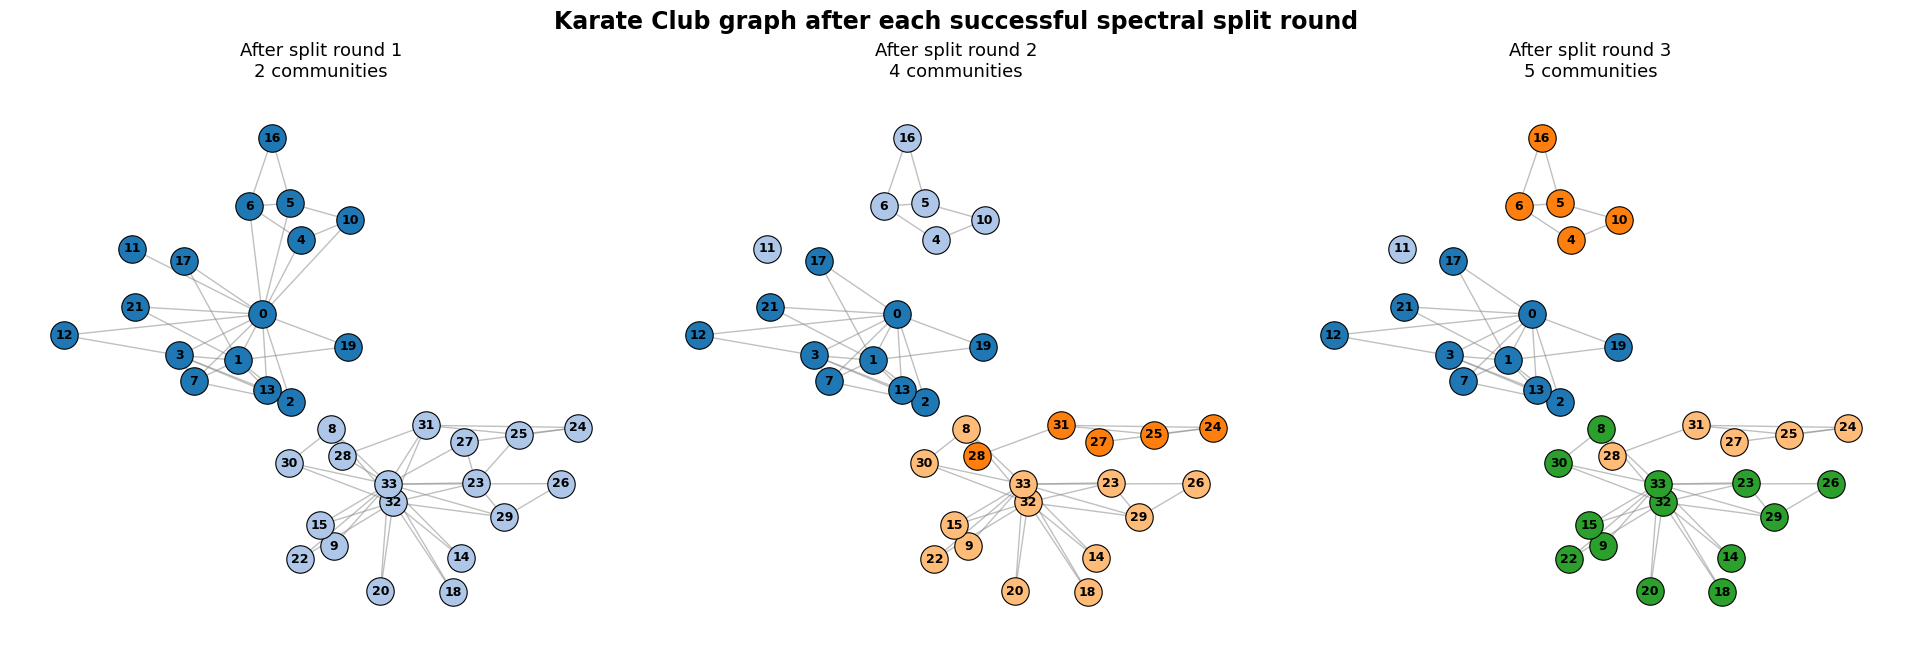

In [9]:
def prune_intercommunity_edges(graph, partition):
    """Return a copy retaining only edges whose endpoints share a community."""
    community_of = {
        node: community_id
        for community_id, community in enumerate(partition)
        for node in community
    }

    pruned = graph.copy()
    cut_edges = [
        (u, v) for u, v in graph.edges()
        if community_of[u] != community_of[v]
    ]
    pruned.remove_edges_from(cut_edges)
    return pruned


# A fixed layout ensures that all split panels use the same node positions.
layout = nx.spring_layout(G, seed=42)
plot_iterations = list(partition_history.keys())[1:]
palette = plt.get_cmap("tab20")

fig, axes = plt.subplots(2, 3, figsize=(19, 12), constrained_layout=True)
axes = axes.ravel()

for ax, iteration in zip(axes, plot_iterations):
    partition = partition_history[iteration]
    H = prune_intercommunity_edges(G, partition)

    nx.draw_networkx_edges(
        H, layout, ax=ax, width=1.0, alpha=0.55, edge_color="0.55"
    )

    for community_id, community in enumerate(partition):
        nx.draw_networkx_nodes(
            H,
            layout,
            nodelist=community,
            ax=ax,
            node_color=[palette(community_id % 20)],
            node_size=390,
            linewidths=0.8,
            edgecolors="black"
        )

    nx.draw_networkx_labels(
        H, layout, ax=ax, font_size=9, font_weight="bold"
    )
    ax.set_title(
        f"After split round {iteration}\n{len(partition)} communities",
        fontsize=13,
        pad=10
    )
    ax.set_axis_off()

# Hide any unused axes if a different graph produces fewer than six rounds.
for ax in axes[len(plot_iterations):]:
    ax.set_visible(False)

fig.suptitle(
    "Karate Club graph after each successful spectral split round",
    fontsize=17,
    fontweight="bold"
)
plt.show()

## 8. Pruning edges and computing node metrics

For every saved partition, we create a pruned copy of the original graph by deleting edges that cross community boundaries. The vertex set is unchanged, so all metric dictionaries contain one value for every node at every iteration, including any node that becomes isolated.

The initial unpruned graph is stored as iteration 0. After each successful split round, NetworkX computes degree centrality, betweenness centrality, closeness centrality, and the clustering coefficient for all nodes.

### What the four metrics measure

| Metric | Definition / interpretation | NetworkX function |
|---|---|---|
| Degree centrality | $C_D(i)=\frac{k_i}{n-1}$; fraction of other vertices directly adjacent to $i$. | `nx.degree_centrality` |
| Betweenness centrality | $C_B(i)=\sum_{s\ne i\ne t}\frac{\sigma_{st}(i)}{\sigma_{st}}$; share of shortest paths through $i$. | `nx.betweenness_centrality` |
| Closeness centrality | $C_C(i)=\frac{n-1}{\sum_{j\ne i}d(i,j)}$ for a connected graph; inverse average shortest-path distance. | `nx.closeness_centrality` |
| Clustering coefficient | $C(i)=\frac{2T(i)}{k_i(k_i-1)}$; fraction of neighbor pairs that are connected. | `nx.clustering` |

Degree and betweenness capture different forms of global importance: direct connectivity and brokerage along shortest paths. Closeness reflects reachability, while clustering is local and can behave differently from the other three measures.

### Metric calculation at every iteration

NetworkX's built-in metric functions are used as requested in the assignment. For disconnected graphs, NetworkX's closeness centrality applies its reachable-component correction; the reported values therefore remain defined after fragmentation instead of treating unreachable distances as finite.

In [10]:
metric_history = {
    "degree_centrality": {},
    "betweenness_centrality": {},
    "closeness_centrality": {},
    "clustering": {}
}
graph_history = {}

for iteration, partition in partition_history.items():
    # Remove inter-community edges, but keep all original vertices.
    H = prune_intercommunity_edges(G, partition)
    graph_history[iteration] = H

    metric_history["degree_centrality"][iteration] = nx.degree_centrality(H)
    metric_history["betweenness_centrality"][iteration] = nx.betweenness_centrality(H)
    metric_history["closeness_centrality"][iteration] = nx.closeness_centrality(H)
    metric_history["clustering"][iteration] = nx.clustering(H)

print("Iteration | Communities | Edges remaining | Connected components")
for iteration, H in graph_history.items():
    print(
        f"{iteration:9d} | {len(partition_history[iteration]):11d} | "
        f"{H.number_of_edges():15d} | {nx.number_connected_components(H):21d}"
    )

assert all(set(H.nodes()) == set(nodes) for H in graph_history.values())
assert all(
    set(metric_history[name][iteration]) == set(nodes)
    for name in metric_history
    for iteration in partition_history
)
print("\nAll four metric snapshots contain all 34 nodes at every iteration.")

Iteration | Communities | Edges remaining | Connected components
        0 |           1 |              78 |                     1
        1 |           2 |              68 |                     2
        2 |           4 |              57 |                     5
        3 |           5 |              57 |                     5

All four metric snapshots contain all 34 nodes at every iteration.


## 9. Evolution of node metrics

The next figure places the four metrics in a single 2-by-2 grid and plots all 34 nodes across the original graph and every split round. To keep the trajectories readable, the four nodes with the highest value at the initial snapshot and the four highest at the final snapshot are highlighted and named in each panel; the remaining nodes are shown as faint lines.

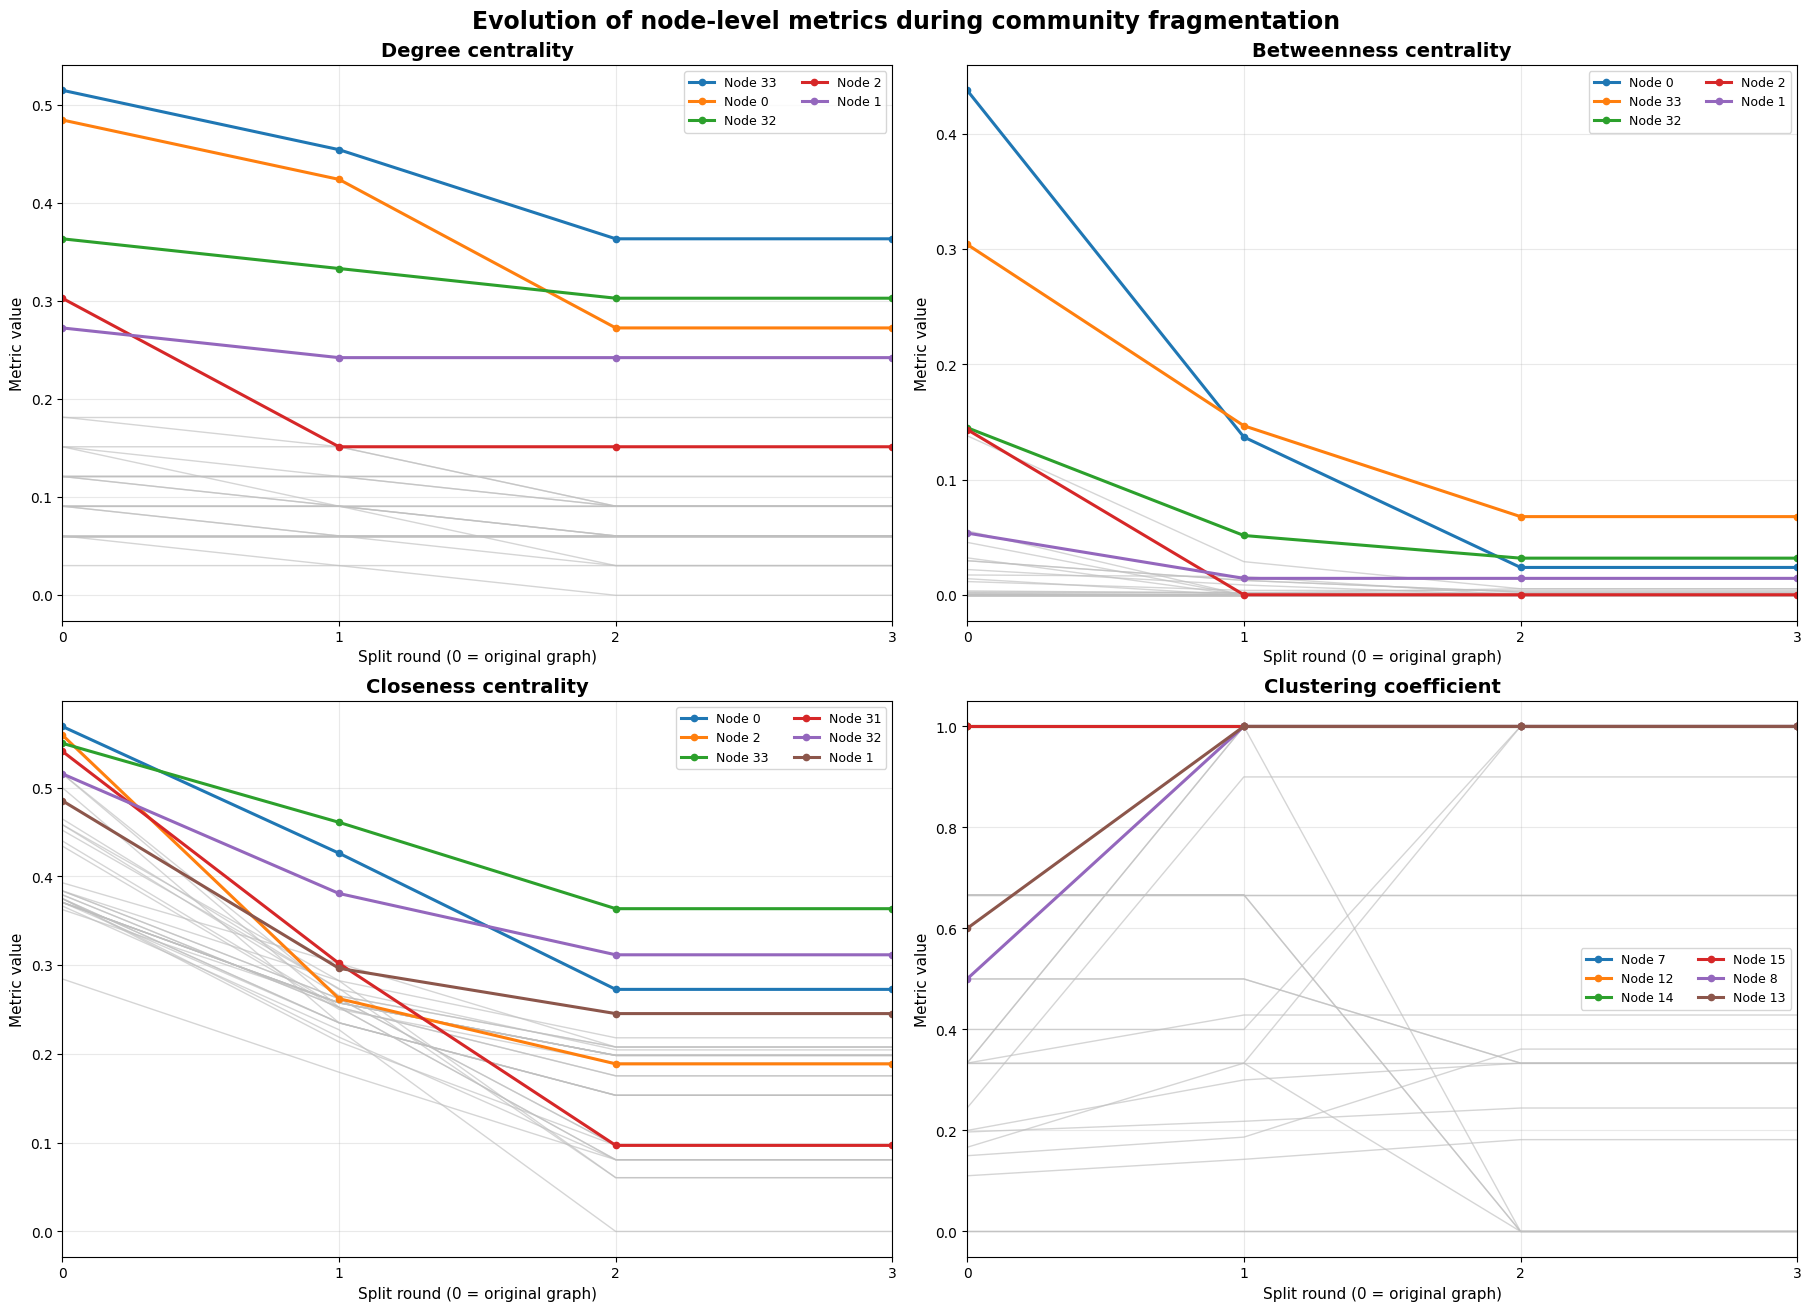

In [11]:
metric_titles = {
    "degree_centrality": "Degree centrality",
    "betweenness_centrality": "Betweenness centrality",
    "closeness_centrality": "Closeness centrality",
    "clustering": "Clustering coefficient"
}

iterations = list(partition_history.keys())
key_colors = plt.get_cmap("tab10")
fig, axes = plt.subplots(2, 2, figsize=(18, 13), constrained_layout=True)
axes = axes.ravel()

for ax, metric_name in zip(axes, metric_titles):
    values_by_iteration = metric_history[metric_name]
    first_values = values_by_iteration[iterations[0]]
    last_values = values_by_iteration[iterations[-1]]

    # Highlight nodes that rank highly at either endpoint.
    top_initial = sorted(
        nodes, key=lambda node: (-first_values[node], node)
    )[:4]
    top_final = sorted(
        nodes, key=lambda node: (-last_values[node], node)
    )[:4]
    key_nodes = list(dict.fromkeys(top_initial + top_final))

    # Plot all other node trajectories in the background.
    for node in nodes:
        if node in key_nodes:
            continue
        values = [values_by_iteration[i][node] for i in iterations]
        ax.plot(
            iterations, values,
            color="0.75", linewidth=1.0, alpha=0.65
        )

    # Highlight and label the key trajectories.
    for color_index, node in enumerate(key_nodes):
        values = [values_by_iteration[i][node] for i in iterations]
        ax.plot(
            iterations, values,
            marker="o", markersize=4.5, linewidth=2.2,
            color=key_colors(color_index % 10), label=f"Node {node}"
        )

    ax.set_title(metric_titles[metric_name], fontsize=14, fontweight="bold")
    ax.set_xlabel("Split round (0 = original graph)", fontsize=11)
    ax.set_ylabel("Metric value", fontsize=11)
    ax.set_xticks(iterations)
    ax.set_xlim(iterations[0], iterations[-1])
    ax.grid(True, alpha=0.28)
    ax.tick_params(labelsize=10)
    ax.legend(fontsize=9, ncol=2, frameon=True, loc="best")

fig.suptitle(
    "Evolution of node-level metrics during community fragmentation",
    fontsize=17,
    fontweight="bold"
)
plt.show()

## 10. Results and discussion

The algorithm performs three successful split rounds, with four individual community splits, and finishes with five communities. The pruned graph goes from 78 edges and one connected component initially to 57 retained edges and five connected components after the final successful round. The number of components can exceed the number of detected communities when a candidate community is already disconnected internally.

The highlighted node trajectories and the endpoint rankings support the following observations:

- **Persistent hubs and bridges:** Node **33** is prominent throughout the fragmentation process: it has the highest degree centrality in the original graph and remains highest after the final pruning; it also has the highest betweenness centrality in the final snapshot. Node **32** remains among the leading nodes for degree, betweenness, and closeness. Node **0** is especially prominent in the original graph, particularly in betweenness, but loses much of this global role after cross-community edges are removed.
- **Degree centrality:** It decreases as edges are deleted because nodes lose direct neighbors, while the normalization remains based on all 34 vertices. For example, node 33 decreases from approximately **0.515** in the original graph to **0.364** in the final pruned graph.
- **Betweenness centrality:** It drops as inter-community bridges disappear and shortest paths become confined to smaller components. Node 0 decreases from approximately **0.438** initially to **0.0241** in the final graph.
- **Closeness centrality:** It generally decreases because vertices in other components become unreachable. NetworkX's disconnected-graph correction keeps the measure defined using reachable vertices.
- **Clustering coefficient:** It is local, so it is not required to decrease monotonically. Removing external links can leave a node's neighbors more tightly connected, while removing edges within a local triangle can reduce its clustering coefficient.

### Sign-splitting edge case

Four tested communities had a positive leading eigenvalue above the threshold, but their leading eigenvectors contained entries of only one sign. The prescribed sign split would therefore create an empty group, so the implementation retains and reports these communities separately. They are not certified as indivisible by the eigenvalue stopping test alone; one other candidate stopped because its leading eigenvalue did not exceed the threshold.

## 11. References

1. Newman, M. E. J. (2006). **Modularity and community structure in networks.** *Proceedings of the National Academy of Sciences*, **103**(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103
2. DSC212: Graph Theory Module. **Research Assignment: Modularity on the Karate Club Graph.** Course handout, 10 pages.

The modularity matrix, modularity objective, leading-eigenvector relaxation, and recursive spectral bisection framework used in this notebook follow the formulation described in Newman (2006) and presented in the DSC212 assignment handout.